<a href="https://colab.research.google.com/github/pudingmatcha/UTS-AI-KELAS-A/blob/main/aduhbuwiwik.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

import dataset

In [ ]:
from google.colab import drive
from pathlib import Path
import tensorflow as tf

drive.mount('/content/drive')

print("Versi TensorFlow:", tf.__version__)

daftar_gpu = tf.config.list_physical_devices('GPU')
print("GPU terdeteksi:", daftar_gpu)

Mounted at /content/drive
Versi TensorFlow: 2.21.0
GPU terdeteksi: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
folder_dataset = Path(
    '/content/drive/MyDrive/TUGAS/AI/KLASIFIKASI BUAH'
)

print("Folder ditemukan:", folder_dataset.is_dir())

if folder_dataset.is_dir():
    print("\nIsi folder dataset:")

    for lokasi in sorted(folder_dataset.iterdir()):
        jenis = "Folder" if lokasi.is_dir() else "File"
        print(jenis, "-", lokasi.name)
else:
    print("Periksa kembali lokasi folder dataset.")

Folder ditemukan: True

Isi folder dataset:
Folder - Test
Folder - Train


 memeriksa struktur folder dan jumlah gambar dataset baru.

In [ ]:
from collections import Counter

ekstensi_gambar = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

jumlah_per_folder = Counter()

for lokasi in folder_dataset.rglob('*'):
    if lokasi.is_file() and lokasi.suffix.lower() in ekstensi_gambar:
        folder_relatif = lokasi.parent.relative_to(folder_dataset)
        jumlah_per_folder[str(folder_relatif)] += 1

print("=== JUMLAH GAMBAR PER FOLDER ===")

for nama_folder, jumlah in sorted(jumlah_per_folder.items()):
    print(f"{nama_folder}: {jumlah} gambar")

total_gambar = sum(jumlah_per_folder.values())

print("\nTotal gambar:", total_gambar)

=== JUMLAH GAMBAR PER FOLDER ===
Test/Overripe: 60 gambar
Test/Ripe: 60 gambar
Test/Unripe: 60 gambar
Train/Overipe: 776 gambar
Train/Ripe: 1826 gambar
Train/Unripe: 1832 gambar

Total gambar: 4614


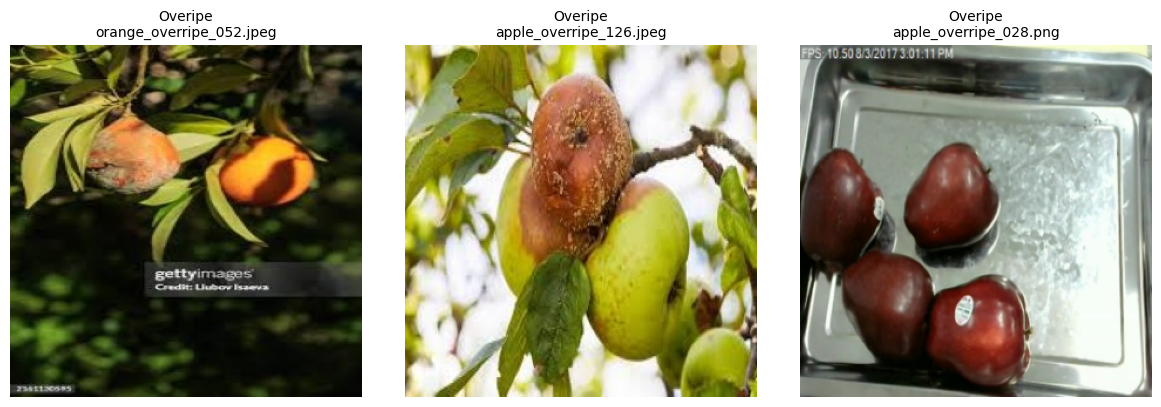

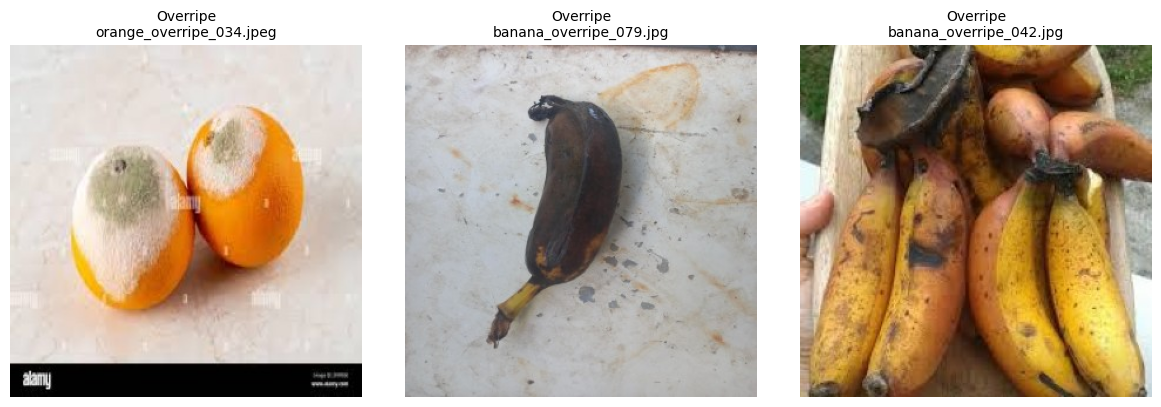

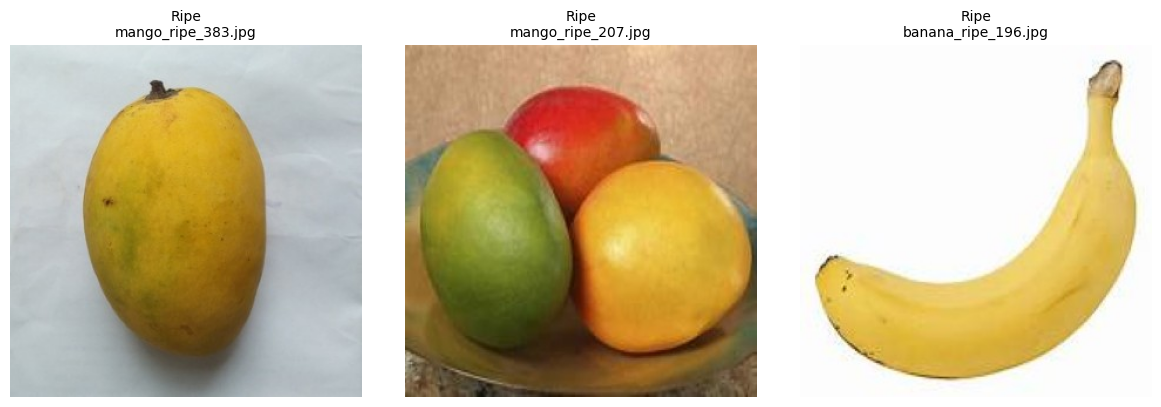

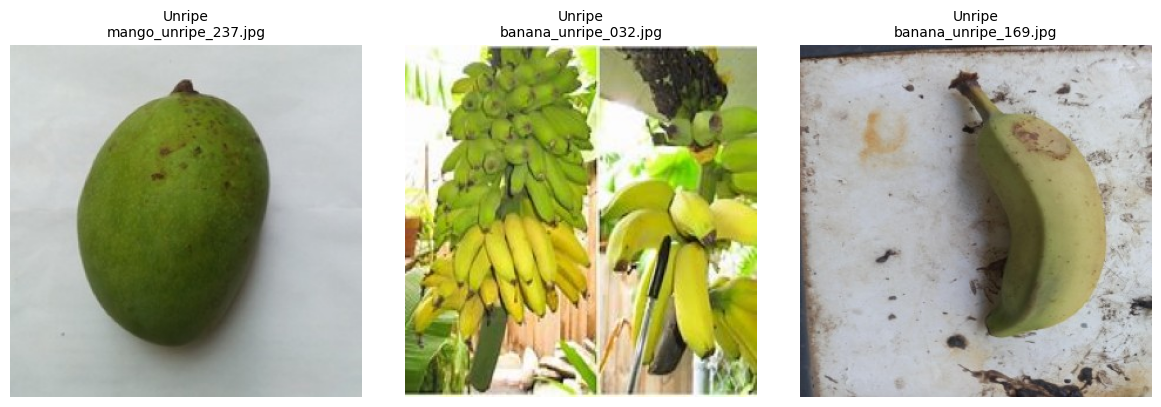

In [ ]:
import random
import matplotlib.pyplot as plt
from PIL import Image

gambar_per_kelas = {}

for lokasi in folder_dataset.rglob('*'):
    if lokasi.is_file() and lokasi.suffix.lower() in ekstensi_gambar:
        nama_kelas = lokasi.parent.name

        if nama_kelas not in gambar_per_kelas:
            gambar_per_kelas[nama_kelas] = []

        gambar_per_kelas[nama_kelas].append(lokasi)

if not gambar_per_kelas:
    raise ValueError("Tidak ada gambar ditemukan.")

jumlah_contoh = 3
pengacak = random.Random(42)

for nama_kelas, daftar_gambar in sorted(gambar_per_kelas.items()):
    gambar_pilihan = pengacak.sample(
        daftar_gambar,
        min(jumlah_contoh, len(daftar_gambar))
    )

    fig, sumbu = plt.subplots(
        1,
        len(gambar_pilihan),
        figsize=(4 * len(gambar_pilihan), 4),
        squeeze=False
    )

    for kolom, lokasi in enumerate(gambar_pilihan):
        ax = sumbu[0, kolom]

        try:
            with Image.open(lokasi) as gambar:
                ax.imshow(gambar.convert('RGB'))

            ax.set_title(
                f"{nama_kelas}\n{lokasi.name[:25]}",
                fontsize=10
            )

        except (OSError, ValueError):
            ax.set_title(f"{nama_kelas}\nGambar gagal dibuka")
            print("Periksa file:", lokasi)

        ax.axis('off')

    plt.tight_layout()
    plt.show()

=== RINGKASAN RESOLUSI ASLI ===


,Lebar,Tinggi
count,2427.0,2427.0
mean,300.0,300.0
std,0.0,0.0
min,300.0,300.0
25%,300.0,300.0
50%,300.0,300.0
75%,300.0,300.0
max,300.0,300.0


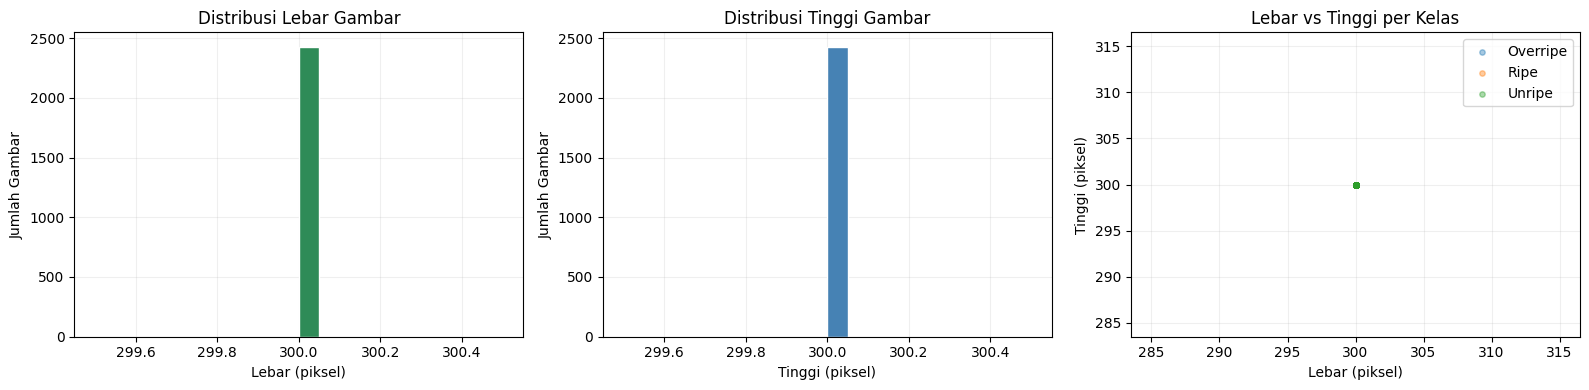

Ukuran berhasil dibaca: 2427
Gagal dibaca: 0


In [ ]:
from PIL import Image
import pandas as pd
import matplotlib.pyplot as plt

data_resolusi = []
gambar_gagal = []

# Baca ukuran asli gambar
for _, baris in tabel_final.iterrows():
    try:
        with Image.open(baris['Lokasi']) as gambar:
            lebar, tinggi = gambar.size

        data_resolusi.append({
            'Kelas': baris['Kelas'],
            'Split': baris['Split'],
            'Lebar': lebar,
            'Tinggi': tinggi
        })

    except (OSError, ValueError, Image.DecompressionBombError):
        gambar_gagal.append(baris['Lokasi'])

tabel_resolusi = pd.DataFrame(data_resolusi)

if tabel_resolusi.empty:
    raise ValueError("Tidak ada ukuran gambar yang berhasil dibaca.")

# Ringkasan ukuran
print("=== RINGKASAN RESOLUSI ASLI ===")
display(
    tabel_resolusi[['Lebar', 'Tinggi']]
    .describe()
    .round(1)
)

# Grafik distribusi ukuran dan hubungan lebar–tinggi
fig, sumbu = plt.subplots(1, 3, figsize=(16, 4))

sumbu[0].hist(
    tabel_resolusi['Lebar'],
    bins=20,
    color='seagreen',
    edgecolor='white'
)
sumbu[0].set_title('Distribusi Lebar Gambar')
sumbu[0].set_xlabel('Lebar (piksel)')
sumbu[0].set_ylabel('Jumlah Gambar')

sumbu[1].hist(
    tabel_resolusi['Tinggi'],
    bins=20,
    color='steelblue',
    edgecolor='white'
)
sumbu[1].set_title('Distribusi Tinggi Gambar')
sumbu[1].set_xlabel('Tinggi (piksel)')
sumbu[1].set_ylabel('Jumlah Gambar')

for kelas, kelompok in tabel_resolusi.groupby('Kelas'):
    sumbu[2].scatter(
        kelompok['Lebar'],
        kelompok['Tinggi'],
        label=kelas,
        alpha=0.4,
        s=15
    )

sumbu[2].set_title('Lebar vs Tinggi per Kelas')
sumbu[2].set_xlabel('Lebar (piksel)')
sumbu[2].set_ylabel('Tinggi (piksel)')
sumbu[2].legend()

for ax in sumbu:
    ax.grid(alpha=0.2)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

print("Ukuran berhasil dibaca:", len(tabel_resolusi))
print("Gagal dibaca:", len(gambar_gagal))

In [ ]:
jumlah_per_split = {
    'train': 0,
    'validation': 0,
    'test': 0,
    'belum_dikenali': 0
}

nama_split = {
    'train': 'train',
    'training': 'train',
    'val': 'validation',
    'valid': 'validation',
    'validation': 'validation',
    'test': 'test',
    'testing': 'test'
}

for lokasi in folder_dataset.rglob('*'):
    if lokasi.is_file() and lokasi.suffix.lower() in ekstensi_gambar:
        bagian_folder = lokasi.relative_to(folder_dataset).parts[:-1]

        split_ditemukan = {
            nama_split[bagian.lower()]
            for bagian in bagian_folder
            if bagian.lower() in nama_split
        }

        if len(split_ditemukan) == 1:
            split = split_ditemukan.pop()
        else:
            split = 'belum_dikenali'

        jumlah_per_split[split] += 1

total_gambar = sum(jumlah_per_split.values())

if total_gambar == 0:
    raise ValueError("Tidak ada gambar ditemukan. Periksa lokasi dataset.")

print("=== PEMBAGIAN DATASET ===")

for split, jumlah in jumlah_per_split.items():
    persentase = jumlah / total_gambar * 100

    print(f"{split}: {jumlah} gambar ({persentase:.2f}%)")

print("\nTotal gambar:", total_gambar)

=== PEMBAGIAN DATASET ===
train: 4434 gambar (96.10%)
validation: 0 gambar (0.00%)
test: 180 gambar (3.90%)
belum_dikenali: 0 gambar (0.00%)

Total gambar: 4614


membuat eda

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pemetaan_split = {
    'train': 'Train',
    'training': 'Train',
    'val': 'Validation',
    'valid': 'Validation',
    'validation': 'Validation',
    'test': 'Test',
    'testing': 'Test'
}

data_gambar = []

for lokasi in sorted(folder_dataset.rglob('*')):
    if lokasi.is_file() and lokasi.suffix.lower() in ekstensi_gambar:
        bagian_folder = lokasi.relative_to(folder_dataset).parts[:-1]

        split_ditemukan = {
            pemetaan_split[bagian.lower()]
            for bagian in bagian_folder
            if bagian.lower() in pemetaan_split
        }

        split = (
            next(iter(split_ditemukan))
            if len(split_ditemukan) == 1
            else 'Belum dikenali'
        )

        data_gambar.append({
            'Lokasi': str(lokasi),
            'Kelas': lokasi.parent.name,
            'Split': split
        })

tabel_gambar = pd.DataFrame(
    data_gambar,
    columns=['Lokasi', 'Kelas', 'Split']
)

if tabel_gambar.empty:
    raise ValueError("Tidak ada gambar ditemukan. Periksa folder_dataset.")

tabel_distribusi = pd.crosstab(
    tabel_gambar['Kelas'],
    tabel_gambar['Split']
)

urutan_split = ['Train', 'Validation', 'Test', 'Belum dikenali']

tabel_distribusi = tabel_distribusi.reindex(
    columns=urutan_split,
    fill_value=0
)

tabel_ringkasan = tabel_distribusi.copy()
tabel_ringkasan['Total'] = tabel_distribusi.sum(axis=1)

display(tabel_ringkasan)
print("Total gambar:", len(tabel_gambar))

Split,Train,Validation,Test,Belum dikenali,Total
Kelas,,,,,
Overipe,776,0,0,0,776
Overripe,0,0,60,0,60
Ripe,1826,0,60,0,1886
Unripe,1832,0,60,0,1892


Total gambar: 4614


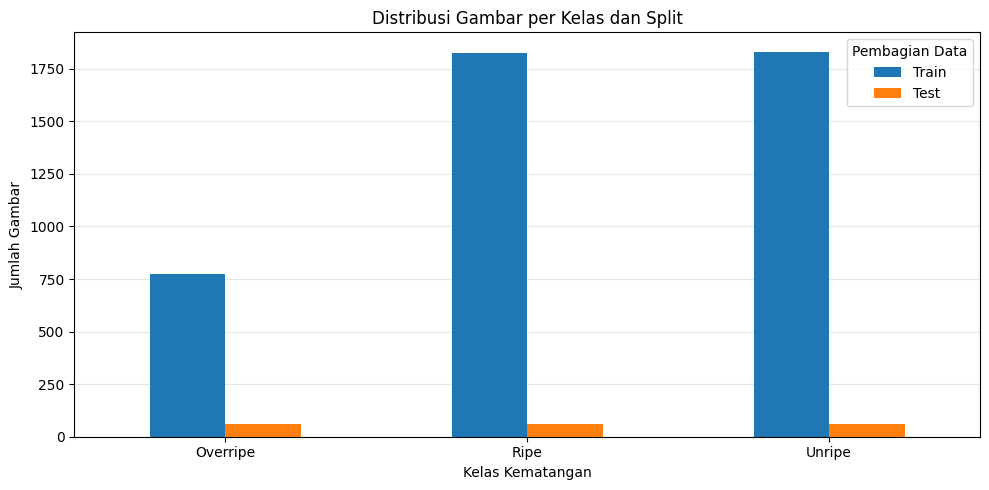

In [ ]:
split_tersedia = [
    nama
    for nama in urutan_split
    if tabel_distribusi[nama].sum() > 0
]

ax = tabel_distribusi[split_tersedia].plot(
    kind='bar',
    figsize=(10, 5),
    rot=0
)

ax.set_title('Distribusi Gambar per Kelas dan Split')
ax.set_xlabel('Kelas Kematangan')
ax.set_ylabel('Jumlah Gambar')

ax.legend(title='Pembagian Data')
ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [ ]:
tabel_gambar['Kelas'] = tabel_gambar['Kelas'].apply(
    lambda nama: 'Overripe'
    if nama.strip().lower() in ['overipe', 'overripe']
    else nama
)

tabel_distribusi = pd.crosstab(
    tabel_gambar['Kelas'],
    tabel_gambar['Split']
)

tabel_distribusi = tabel_distribusi.reindex(
    columns=urutan_split,
    fill_value=0
)

tabel_ringkasan = tabel_distribusi.copy()
tabel_ringkasan['Total'] = tabel_distribusi.sum(axis=1)

display(tabel_ringkasan)

Split,Train,Validation,Test,Belum dikenali,Total
Kelas,,,,,
Overripe,776,0,60,0,836
Ripe,1826,0,60,0,1886
Unripe,1832,0,60,0,1892


pemeriksaan data duplikat dan data leakage (data cleaning)

In [ ]:
import hashlib
from pathlib import Path

data_hash = []

for nomor, lokasi in enumerate(tabel_gambar['Lokasi'], start=1):
    nilai_hash = hashlib.sha256()

    with open(lokasi, 'rb') as file:
        for potongan in iter(lambda: file.read(1024 * 1024), b''):
            nilai_hash.update(potongan)

    data_hash.append(nilai_hash.hexdigest())

    if nomor % 500 == 0:
        print(f"Sudah diperiksa: {nomor} gambar")

tabel_hash = tabel_gambar.copy()
tabel_hash['Hash'] = data_hash

tabel_duplikat = tabel_hash[
    tabel_hash.duplicated(subset='Hash', keep=False)
].sort_values('Hash')

jumlah_split_per_hash = tabel_hash.groupby('Hash')['Split'].nunique()

hash_lintas_split = jumlah_split_per_hash[
    jumlah_split_per_hash > 1
].index

tabel_leakage = tabel_hash[
    tabel_hash['Hash'].isin(hash_lintas_split)
].sort_values(['Hash', 'Split'])

print("\n=== HASIL PEMERIKSAAN ===")
print("Total gambar:", len(tabel_hash))
print("Grup file identik:", tabel_duplikat['Hash'].nunique())
print("Jumlah file dalam grup identik:", len(tabel_duplikat))
print("Grup file identik lintas split:", len(hash_lintas_split))

Sudah diperiksa: 500 gambar
Sudah diperiksa: 1000 gambar
Sudah diperiksa: 1500 gambar
Sudah diperiksa: 2000 gambar
Sudah diperiksa: 2500 gambar
Sudah diperiksa: 3000 gambar
Sudah diperiksa: 3500 gambar
Sudah diperiksa: 4000 gambar
Sudah diperiksa: 4500 gambar

=== HASIL PEMERIKSAAN ===
Total gambar: 4614
Grup file identik: 157
Jumlah file dalam grup identik: 372
Grup file identik lintas split: 16


In [ ]:
if tabel_leakage.empty:
    print("Tidak ditemukan file identik lintas split.")
else:
    display(
        tabel_leakage[['Kelas', 'Split', 'Lokasi']]
        .head(30)
    )

if (tabel_hash['Split'] == 'Belum dikenali').any():
    print(
        "Perhatian: ada split yang belum dikenali. "
        "Perbaiki pemetaan folder sebelum menyimpulkan hasil leakage."
    )

,Kelas,Split,Lokasi
116,Ripe,Test,/content/drive/MyDrive/TUGAS/AI/KLASIFIKASI BU...
2722,Ripe,Train,/content/drive/MyDrive/TUGAS/AI/KLASIFIKASI BU...
55,Overripe,Test,/content/drive/MyDrive/TUGAS/AI/KLASIFIKASI BU...
894,Overripe,Train,/content/drive/MyDrive/TUGAS/AI/KLASIFIKASI BU...
145,Unripe,Test,/content/drive/MyDrive/TUGAS/AI/KLASIFIKASI BU...
3526,Unripe,Train,/content/drive/MyDrive/TUGAS/AI/KLASIFIKASI BU...
3527,Unripe,Train,/content/drive/MyDrive/TUGAS/AI/KLASIFIKASI BU...
3543,Unripe,Train,/content/drive/MyDrive/TUGAS/AI/KLASIFIKASI BU...
166,Unripe,Test,/content/drive/MyDrive/TUGAS/AI/KLASIFIKASI BU...
4315,Unripe,Train,/content/drive/MyDrive/TUGAS/AI/KLASIFIKASI BU...


In [ ]:
print("=== FILE IDENTIK LINTAS SPLIT ===")

display(
    tabel_leakage[['Hash', 'Kelas', 'Split', 'Lokasi']]
)

jumlah_kelas_per_hash = (
    tabel_hash.groupby('Hash')['Kelas'].nunique()
)

hash_label_berbeda = jumlah_kelas_per_hash[
    jumlah_kelas_per_hash > 1
].index

tabel_label_berbeda = tabel_hash[
    tabel_hash['Hash'].isin(hash_label_berbeda)
].sort_values(['Hash', 'Kelas'])

print(
    "\nGrup gambar identik dengan label berbeda:",
    len(hash_label_berbeda)
)

if not tabel_label_berbeda.empty:
    display(
        tabel_label_berbeda[['Hash', 'Kelas', 'Split', 'Lokasi']]
    )

=== FILE IDENTIK LINTAS SPLIT ===


,Hash,Kelas,Split,Lokasi
116,26d293a330cb1f0cb9fb381ad38765988eeacc2dc1454c...,Ripe,Test,/content/drive/MyDrive/TUGAS/AI/KLASIFIKASI BU...
2722,26d293a330cb1f0cb9fb381ad38765988eeacc2dc1454c...,Ripe,Train,/content/drive/MyDrive/TUGAS/AI/KLASIFIKASI BU...
55,329c079a1d27fbc7570f3ac8eedec6ee676edad9e62616...,Overripe,Test,/content/drive/MyDrive/TUGAS/AI/KLASIFIKASI BU...
894,329c079a1d27fbc7570f3ac8eedec6ee676edad9e62616...,Overripe,Train,/content/drive/MyDrive/TUGAS/AI/KLASIFIKASI BU...
145,3bfefd89bd5809dd8e082435c2b984491ca395de3e7b72...,Unripe,Test,/content/drive/MyDrive/TUGAS/AI/KLASIFIKASI BU...
3526,3bfefd89bd5809dd8e082435c2b984491ca395de3e7b72...,Unripe,Train,/content/drive/MyDrive/TUGAS/AI/KLASIFIKASI BU...
3527,3bfefd89bd5809dd8e082435c2b984491ca395de3e7b72...,Unripe,Train,/content/drive/MyDrive/TUGAS/AI/KLASIFIKASI BU...
3543,3bfefd89bd5809dd8e082435c2b984491ca395de3e7b72...,Unripe,Train,/content/drive/MyDrive/TUGAS/AI/KLASIFIKASI BU...
166,415c7e6360cdb282e9c069906bd93d00240464c2b6b7a7...,Unripe,Test,/content/drive/MyDrive/TUGAS/AI/KLASIFIKASI BU...
4315,415c7e6360cdb282e9c069906bd93d00240464c2b6b7a7...,Unripe,Train,/content/drive/MyDrive/TUGAS/AI/KLASIFIKASI BU...



Grup gambar identik dengan label berbeda: 0


In [ ]:
prioritas_split = {
    'Test': 0,
    'Validation': 1,
    'Train': 2
}

split_tidak_dikenali = (
    ~tabel_hash['Split'].isin(prioritas_split)
)

if split_tidak_dikenali.any():
    raise ValueError(
        "Ada split yang belum dikenali. Perbaiki pemetaan split dahulu."
    )

if (tabel_hash.groupby('Hash')['Kelas'].nunique() > 1).any():
    raise ValueError(
        "Masih ada gambar identik dengan label berbeda."
    )

tabel_urut = tabel_hash.copy()

tabel_urut['Prioritas'] = (
    tabel_urut['Split'].map(prioritas_split)
)

tabel_urut = tabel_urut.sort_values(
    ['Prioritas', 'Lokasi']
)

tabel_bersih = (
    tabel_urut
    .drop_duplicates(subset='Hash', keep='first')
    .drop(columns='Prioritas')
    .reset_index(drop=True)
)

print("Jumlah sebelum:", len(tabel_hash))
print("Jumlah setelah:", len(tabel_bersih))
print("Salinan disisihkan:", len(tabel_hash) - len(tabel_bersih))

display(
    pd.crosstab(
        tabel_bersih['Kelas'],
        tabel_bersih['Split']
    )
)

Jumlah sebelum: 4614
Jumlah setelah: 4399
Salinan disisihkan: 215


Split,Test,Train
Kelas,,
Overripe,60,747
Ripe,60,1775
Unripe,60,1697


In [ ]:
batas_per_kelas = 750
seed = 42

train_bersih = tabel_bersih[
    tabel_bersih['Split'] == 'Train'
].copy()

daftar_train = []

for nama_kelas, kelompok in train_bersih.groupby('Kelas'):
    jumlah_diambil = min(batas_per_kelas, len(kelompok))

    pilihan = kelompok.sample(
        n=jumlah_diambil,
        random_state=seed
    )

    daftar_train.append(pilihan)

train_dipertahankan = pd.concat(
    daftar_train,
    ignore_index=True
)

lokasi_dipertahankan = set(train_dipertahankan['Lokasi'])

train_asli = tabel_hash[
    tabel_hash['Split'] == 'Train'
].copy()

daftar_hapus = train_asli[
    ~train_asli['Lokasi'].isin(lokasi_dipertahankan)
].copy()

print("=== TRAIN YANG DIPERTAHANKAN ===")
display(
    train_dipertahankan.groupby('Kelas')
    .size()
    .reset_index(name='Jumlah')
)

print("Total file Train yang akan dihapus:", len(daftar_hapus))
print("Termasuk gambar berlebih dan salinan Train yang disisihkan.")

display(daftar_hapus[['Kelas', 'Lokasi']].head(10))

=== TRAIN YANG DIPERTAHANKAN ===


,Kelas,Jumlah
0,Overripe,747
1,Ripe,750
2,Unripe,750


Total file Train yang akan dihapus: 2187
Termasuk gambar berlebih dan salinan Train yang disisihkan.


,Kelas,Lokasi
195,Overripe,/content/drive/MyDrive/TUGAS/AI/KLASIFIKASI BU...
199,Overripe,/content/drive/MyDrive/TUGAS/AI/KLASIFIKASI BU...
200,Overripe,/content/drive/MyDrive/TUGAS/AI/KLASIFIKASI BU...
204,Overripe,/content/drive/MyDrive/TUGAS/AI/KLASIFIKASI BU...
214,Overripe,/content/drive/MyDrive/TUGAS/AI/KLASIFIKASI BU...
215,Overripe,/content/drive/MyDrive/TUGAS/AI/KLASIFIKASI BU...
216,Overripe,/content/drive/MyDrive/TUGAS/AI/KLASIFIKASI BU...
218,Overripe,/content/drive/MyDrive/TUGAS/AI/KLASIFIKASI BU...
220,Overripe,/content/drive/MyDrive/TUGAS/AI/KLASIFIKASI BU...
221,Overripe,/content/drive/MyDrive/TUGAS/AI/KLASIFIKASI BU...


In [ ]:
from pathlib import Path

lokasi_test = set(
    tabel_hash.loc[tabel_hash['Split'] == 'Test', 'Lokasi']
)

assert set(daftar_hapus['Lokasi']).isdisjoint(lokasi_test), (
    "Penghapusan dihentikan: ada lokasi Test dalam daftar."
)

jumlah_dihapus = 0

for lokasi in daftar_hapus['Lokasi'].unique():
    file_gambar = Path(lokasi)

    if file_gambar.is_file():
        file_gambar.unlink()
        jumlah_dihapus += 1

tabel_bersih = pd.concat(
    [
        train_dipertahankan,
        tabel_bersih[tabel_bersih['Split'] != 'Train']
    ],
    ignore_index=True
)

lokasi_dihapus = set(daftar_hapus['Lokasi'])

tabel_gambar = tabel_gambar[
    ~tabel_gambar['Lokasi'].isin(lokasi_dihapus)
].copy()

tabel_hash = tabel_hash[
    ~tabel_hash['Lokasi'].isin(lokasi_dihapus)
].copy()

print("File berhasil dihapus:", jumlah_dihapus)

display(
    pd.crosstab(
        tabel_bersih['Kelas'],
        tabel_bersih['Split']
    )
)

File berhasil dihapus: 2187


Split,Test,Train
Kelas,,
Overripe,60,747
Ripe,60,750
Unripe,60,750


In [ ]:
def buat_empat_orientasi(gambar, label):
    empat_gambar = tf.stack([
        gambar,
        tf.image.rot90(gambar, k=3),
        tf.image.rot90(gambar, k=2),
        tf.image.rot90(gambar, k=1)
    ])

    empat_label = tf.repeat(label, repeats=4)

    return tf.data.Dataset.from_tensor_slices(
        (empat_gambar, empat_label)
    )


def buat_dataset(tabel, training=False):
    lokasi = tabel['Lokasi'].astype(str).to_numpy()

    label = (
        tabel['Kelas']
        .map(nomor_kelas)
        .to_numpy(dtype=np.int32)
    )

    dataset = tf.data.Dataset.from_tensor_slices(
        (lokasi, label)
    )

    dataset = dataset.map(
        baca_gambar,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if training:
        dataset = dataset.flat_map(buat_empat_orientasi)

        dataset = dataset.shuffle(
            buffer_size=256,
            seed=seed,
            reshuffle_each_iteration=True
        )

    dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset

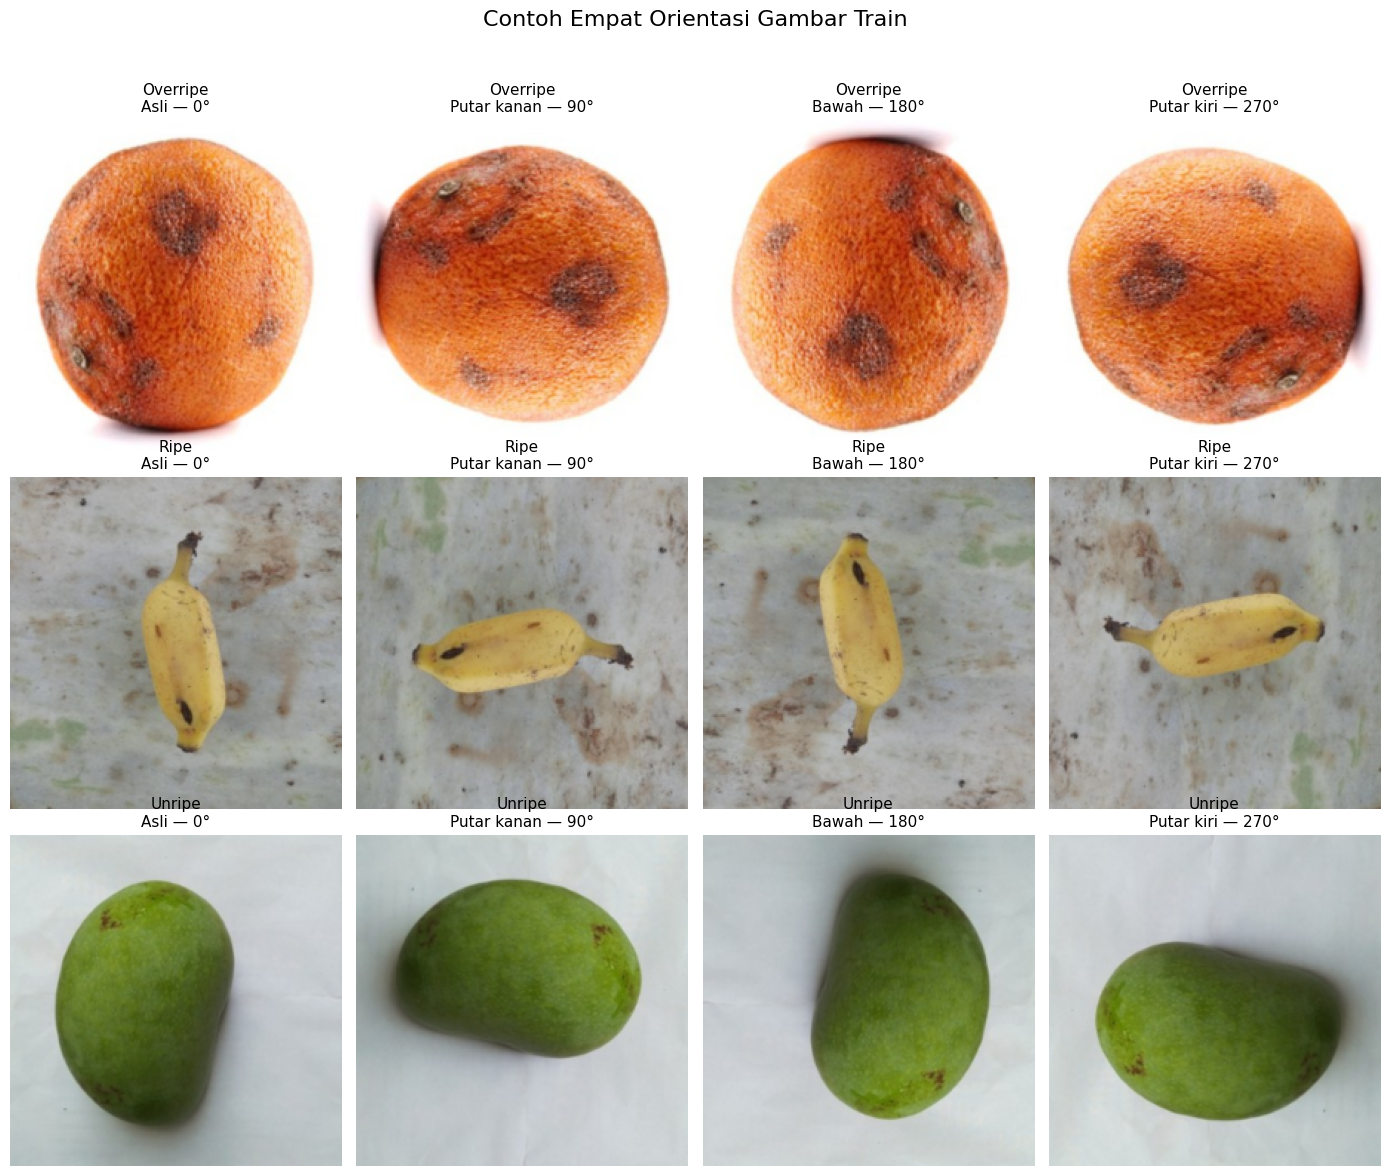

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

orientasi = [
    ('Asli — 0°', None),
    ('Putar kanan — 90°', Image.Transpose.ROTATE_270),
    ('Bawah — 180°', Image.Transpose.ROTATE_180),
    ('Putar kiri — 270°', Image.Transpose.ROTATE_90)
]

contoh_train = tabel_final[
    tabel_final['Split'] == 'Train'
]

daftar_kelas = sorted(contoh_train['Kelas'].unique())

fig, sumbu = plt.subplots(
    len(daftar_kelas),
    4,
    figsize=(14, 4 * len(daftar_kelas)),
    squeeze=False
)

for baris, kelas in enumerate(daftar_kelas):
    pilihan = contoh_train[
        contoh_train['Kelas'] == kelas
    ].sample(n=1, random_state=42)

    lokasi = pilihan.iloc[0]['Lokasi']

    with Image.open(lokasi) as gambar:
        gambar_asli = gambar.convert('RGB').resize(
            (224, 224),
            resample=Image.Resampling.BILINEAR
        )

    for kolom, (judul, rotasi) in enumerate(orientasi):
        if rotasi is None:
            gambar_tampil = gambar_asli
        else:
            gambar_tampil = gambar_asli.transpose(rotasi)

        ax = sumbu[baris, kolom]

        ax.imshow(gambar_tampil)
        ax.set_title(f"{kelas}\n{judul}", fontsize=11)
        ax.axis('off')

plt.suptitle(
    'Contoh Empat Orientasi Gambar Train',
    fontsize=16
)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [ ]:
jumlah_data = pd.crosstab(
    tabel_final['Kelas'],
    tabel_final['Split']
).reindex(
    columns=['Train', 'Validation', 'Test'],
    fill_value=0
)

jumlah_data = jumlah_data.rename(
    columns={'Train': 'Train Asli'}
)

jumlah_data['Train Setelah Augmentasi'] = (
    jumlah_data['Train Asli'] * 4
)

jumlah_data = jumlah_data[
    ['Train Asli', 'Train Setelah Augmentasi', 'Validation', 'Test']
]

jumlah_data.loc['TOTAL'] = jumlah_data.sum()

display(jumlah_data)

total_setelah = (
    jumlah_data.loc['TOTAL', 'Train Setelah Augmentasi']
    + jumlah_data.loc['TOTAL', 'Validation']
    + jumlah_data.loc['TOTAL', 'Test']
)

print("Total contoh seluruh split setelah augmentasi:", total_setelah)

Split,Train Asli,Train Setelah Augmentasi,Validation,Test
Kelas,,,,
Overripe,635,2540,112,60
Ripe,637,2548,113,60
Unripe,637,2548,113,60
TOTAL,1909,7636,338,180


Total contoh seluruh split setelah augmentasi: 8154


data splitting

In [ ]:
import tensorflow as tf
import numpy as np
from PIL import Image

def baca_dengan_pil(lokasi):
    lokasi = np.asarray(lokasi).item().decode('utf-8')

    with Image.open(lokasi) as gambar:
        gambar = gambar.convert('RGB')

        gambar = gambar.resize(
            (ukuran_gambar[1], ukuran_gambar[0]),
            resample=Image.Resampling.BILINEAR
        )

        array_gambar = np.array(
            gambar,
            dtype=np.float32
        )

    return array_gambar


def baca_gambar(lokasi, label):
    gambar = tf.numpy_function(
        baca_dengan_pil,
        [lokasi],
        tf.float32
    )

    gambar.set_shape(
        (ukuran_gambar[0], ukuran_gambar[1], 3)
    )

    return gambar, label


print("Fungsi pembaca gambar sudah siap.")

Fungsi pembaca gambar sudah siap.


In [ ]:
# 1. Ambil daftar gambar setiap split
data_train = tabel_final[
    tabel_final['Split'] == 'Train'
].copy()

data_validation = tabel_final[
    tabel_final['Split'] == 'Validation'
].copy()

data_test = tabel_final[
    tabel_final['Split'] == 'Test'
].copy()

# 2. Pastikan tidak ada hash identik yang berulang
assert tabel_final['Hash'].is_unique, (
    "Masih ada gambar identik dalam tabel_final."
)

# 3. Buat dataset: augmentasi hanya pada Train
dataset_train = buat_dataset(
    data_train,
    training=True
)

dataset_validation = buat_dataset(
    data_validation,
    training=False
)

dataset_test = buat_dataset(
    data_test,
    training=False
)

# 4. Tampilkan jumlah sumber dan contoh yang diproses
ringkasan = pd.DataFrame({
    'Split': ['Train', 'Validation', 'Test'],
    'Gambar Sumber': [
        len(data_train),
        len(data_validation),
        len(data_test)
    ],
    'Contoh yang Diproses': [
        len(data_train) * 4,
        len(data_validation),
        len(data_test)
    ]
})

ringkasan['Persentase Gambar Sumber (%)'] = (
    ringkasan['Gambar Sumber']
    / ringkasan['Gambar Sumber'].sum()
    * 100
).round(2)

display(ringkasan)

,Split,Gambar Sumber,Contoh yang Diproses,Persentase Gambar Sumber (%)
0,Train,1909,7636,78.66
1,Validation,338,338,13.93
2,Test,180,180,7.42


pembuatan model

In [ ]:
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import EfficientNetB0

tf.keras.utils.set_random_seed(seed)

model_dasar = EfficientNetB0(
    include_top=False,
    weights='imagenet',
    input_shape=(*ukuran_gambar, 3)
)

model_dasar.trainable = False

masukan = layers.Input(
    shape=(*ukuran_gambar, 3)
)

fitur = model_dasar(masukan, training=False)

fitur = layers.GlobalAveragePooling2D()(fitur)

fitur = layers.Dropout(0.2)(fitur)

keluaran = layers.Dense(
    len(nama_kelas),
    activation='softmax'
)(fitur)

model = Model(
    inputs=masukan,
    outputs=keluaran,
    name='klasifikasi_kematangan_buah'
)

print("Urutan kelas:", nama_kelas)
model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Urutan kelas: ['Overripe', 'Ripe', 'Unripe']


Model: "klasifikasi_kematangan_buah"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,053,414 (15.46 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [ ]:
learning_rate = 0.001

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=learning_rate
    ),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Model siap untuk training.")

Model siap untuk training.


In [ ]:
from pathlib import Path
import json

folder_hasil = Path(
    '/content/drive/MyDrive/klasifikasi_buah/eksperimen_01'
)

folder_hasil.mkdir(parents=True, exist_ok=True)

file_model_terbaik = folder_hasil / 'model_terbaik.keras'
file_riwayat = folder_hasil / 'riwayat_training.csv'

if file_model_terbaik.exists() or file_riwayat.exists():
    raise FileExistsError(
        "Hasil eksperimen sudah ada. Ganti nama folder eksperimen."
    )

with open(folder_hasil / 'nama_kelas.json', 'w') as file:
    json.dump(nama_kelas, file, indent=2)

tabel_final.to_csv(
    folder_hasil / 'pembagian_dataset.csv',
    index=False
)

print("Lokasi penyimpanan:", folder_hasil)

Lokasi penyimpanan: /content/drive/MyDrive/klasifikasi_buah/eksperimen_01


In [ ]:
maksimum_epoch = 50
patience = 10

callback_training = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=patience,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(file_model_terbaik),
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        filename=str(file_riwayat)
    )
]

In [ ]:
riwayat_training = model.fit(
    dataset_train,
    validation_data=dataset_validation,
    epochs=maksimum_epoch,
    callbacks=callback_training,
    verbose=1
)

Epoch 1/50
    478/Unknown 90s 91ms/step - accuracy: 0.7971 - loss: 0.5166

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: val_loss improved from None to 0.25225, saving model to /content/drive/MyDrive/klasifikasi_buah/eksperimen_01/model_terbaik.keras

Epoch 1: finished saving model to /content/drive/MyDrive/klasifikasi_buah/eksperimen_01/model_terbaik.keras
478/478 ━━━━━━━━━━━━━━━━━━━━ 120s 155ms/step - accuracy: 0.8559 - loss: 0.3762 - val_accuracy: 0.9024 - val_loss: 0.2522
Epoch 2/50
476/478 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.9112 - loss: 0.2446
Epoch 2: val_loss improved from 0.25225 to 0.21596, saving model to /content/drive/MyDrive/klasifikasi_buah/eksperimen_01/model_terbaik.keras

Epoch 2: finished saving model to /content/drive/MyDrive/klasifikasi_buah/eksperimen_01/model_terbaik.keras
478/478 ━━━━━━━━━━━━━━━━━━━━ 49s 36ms/step - accuracy: 0.9179 - loss: 0.2244 - val_accuracy: 0.9083 - val_loss: 0.2160
Epoch 3/50
478/478 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.9187 - loss: 0.2065
Epoch 3: val_loss improved from 0.21596 to 0.18605, saving model to /content/drive/MyD

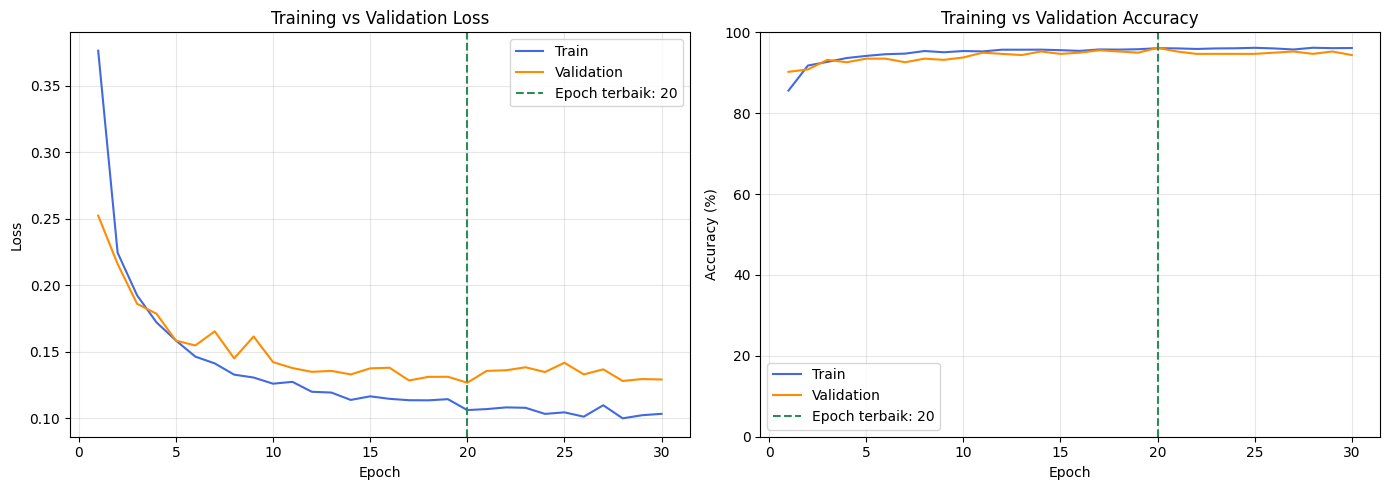

Jumlah epoch selesai: 30
Epoch terbaik berdasarkan val_loss: 20
Validation loss terbaik: 0.1267
Validation accuracy pada epoch tersebut: 96.15%
Grafik disimpan di: /content/drive/MyDrive/klasifikasi_buah/eksperimen_01/grafik_training.png


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Baca catatan hasil training
tabel_riwayat = pd.read_csv(file_riwayat)

# CSVLogger mencatat epoch mulai dari 0
epoch = tabel_riwayat['epoch'] + 1

# Cari epoch dengan validation loss terendah
baris_terbaik = tabel_riwayat['val_loss'].idxmin()
epoch_terbaik = int(epoch.loc[baris_terbaik])

# Buat dua grafik berdampingan
fig, sumbu = plt.subplots(1, 2, figsize=(14, 5))

# Grafik loss
sumbu[0].plot(
    epoch, tabel_riwayat['loss'],
    label='Train', color='royalblue'
)

sumbu[0].plot(
    epoch, tabel_riwayat['val_loss'],
    label='Validation', color='darkorange'
)

sumbu[0].set_title('Training vs Validation Loss')
sumbu[0].set_xlabel('Epoch')
sumbu[0].set_ylabel('Loss')

# Grafik accuracy dalam persen
sumbu[1].plot(
    epoch, tabel_riwayat['accuracy'] * 100,
    label='Train', color='royalblue'
)

sumbu[1].plot(
    epoch, tabel_riwayat['val_accuracy'] * 100,
    label='Validation', color='darkorange'
)

sumbu[1].set_title('Training vs Validation Accuracy')
sumbu[1].set_xlabel('Epoch')
sumbu[1].set_ylabel('Accuracy (%)')
sumbu[1].set_ylim(0, 100)

# Tandai epoch terbaik pada kedua grafik
for ax in sumbu:
    ax.axvline(
        epoch_terbaik,
        color='seagreen',
        linestyle='--',
        label=f'Epoch terbaik: {epoch_terbaik}'
    )

    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()

# Simpan grafik ke folder hasil di Google Drive
file_grafik = folder_hasil / 'grafik_training.png'

plt.savefig(
    file_grafik,
    dpi=200,
    bbox_inches='tight'
)

plt.show()

print("Jumlah epoch selesai:", len(tabel_riwayat))
print("Epoch terbaik berdasarkan val_loss:", epoch_terbaik)
print(
    "Validation loss terbaik:",
    round(tabel_riwayat.loc[baris_terbaik, 'val_loss'], 4)
)
print(
    "Validation accuracy pada epoch tersebut:",
    f"{tabel_riwayat.loc[baris_terbaik, 'val_accuracy'] * 100:.2f}%"
)
print("Grafik disimpan di:", file_grafik)

fine tuning

In [ ]:
import tensorflow as tf

model_finetuning = tf.keras.models.load_model(
    file_model_terbaik,
    compile=False
)

# Ambil EfficientNetB0 yang berada di dalam model
dasar_finetuning = next(
    lapisan
    for lapisan in model_finetuning.layers
    if isinstance(lapisan, tf.keras.Model)
    and 'efficientnet' in lapisan.name.lower()
)

jumlah_lapisan_dibuka = 30

dasar_finetuning.trainable = True

batas_beku = (
    len(dasar_finetuning.layers) - jumlah_lapisan_dibuka
)

for nomor, lapisan in enumerate(dasar_finetuning.layers):
    lapisan.trainable = (
        nomor >= batas_beku
        and not isinstance(
            lapisan,
            tf.keras.layers.BatchNormalization
        )
    )

learning_rate_finetuning = 0.00001

model_finetuning.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=learning_rate_finetuning
    ),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Model dasar:", dasar_finetuning.name)
print(
    "Lapisan dasar yang dibuka:",
    sum(lapisan.trainable for lapisan in dasar_finetuning.layers)
)

Model dasar: efficientnetb0
Lapisan dasar yang dibuka: 23


In [ ]:
folder_finetuning = folder_hasil / 'finetuning_01'
folder_finetuning.mkdir(parents=True, exist_ok=True)

file_model_finetuning = (
    folder_finetuning / 'model_finetuning_terbaik.keras'
)

file_riwayat_finetuning = (
    folder_finetuning / 'riwayat_finetuning.csv'
)

if (
    file_model_finetuning.exists()
    or file_riwayat_finetuning.exists()
):
    raise FileExistsError(
        "Hasil fine-tuning sudah ada. Ganti nama folder finetuning_01."
    )

maksimum_epoch_finetuning = 20
patience_finetuning = 5

callback_finetuning = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=patience_finetuning,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(file_model_finetuning),
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        filename=str(file_riwayat_finetuning)
    )
]

In [ ]:
riwayat_finetuning = model_finetuning.fit(
    dataset_train,
    validation_data=dataset_validation,
    epochs=maksimum_epoch_finetuning,
    callbacks=callback_finetuning,
    verbose=1
)

Epoch 1/20
    478/Unknown 64s 71ms/step - accuracy: 0.9608 - loss: 0.1076

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: val_loss improved from None to 0.11817, saving model to /content/drive/MyDrive/klasifikasi_buah/eksperimen_01/finetuning_01/model_finetuning_terbaik.keras

Epoch 1: finished saving model to /content/drive/MyDrive/klasifikasi_buah/eksperimen_01/finetuning_01/model_finetuning_terbaik.keras
478/478 ━━━━━━━━━━━━━━━━━━━━ 88s 122ms/step - accuracy: 0.9629 - loss: 0.1011 - val_accuracy: 0.9586 - val_loss: 0.1182
Epoch 2/20
477/478 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.9656 - loss: 0.0909
Epoch 2: val_loss improved from 0.11817 to 0.11270, saving model to /content/drive/MyDrive/klasifikasi_buah/eksperimen_01/finetuning_01/model_finetuning_terbaik.keras

Epoch 2: finished saving model to /content/drive/MyDrive/klasifikasi_buah/eksperimen_01/finetuning_01/model_finetuning_terbaik.keras
478/478 ━━━━━━━━━━━━━━━━━━━━ 24s 39ms/step - accuracy: 0.9687 - loss: 0.0831 - val_accuracy: 0.9615 - val_loss: 0.1127
Epoch 3/20
478/478 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.9693 - 

In [ ]:
import pandas as pd

riwayat_awal = pd.read_csv(file_riwayat)
riwayat_ft = pd.read_csv(file_riwayat_finetuning)

perbandingan = pd.DataFrame({
    'Tahap': ['Training awal', 'Fine-tuning'],
    'Validation Loss Terbaik': [
        riwayat_awal['val_loss'].min(),
        riwayat_ft['val_loss'].min()
    ]
})

display(perbandingan)

if riwayat_ft['val_loss'].min() < riwayat_awal['val_loss'].min():
    print("Fine-tuning menghasilkan validation loss lebih rendah.")
else:
    print("Model awal tetap lebih baik atau sama berdasarkan val_loss.")

,Tahap,Validation Loss Terbaik
0,Training awal,0.12674
1,Fine-tuning,0.10903


Fine-tuning menghasilkan validation loss lebih rendah.


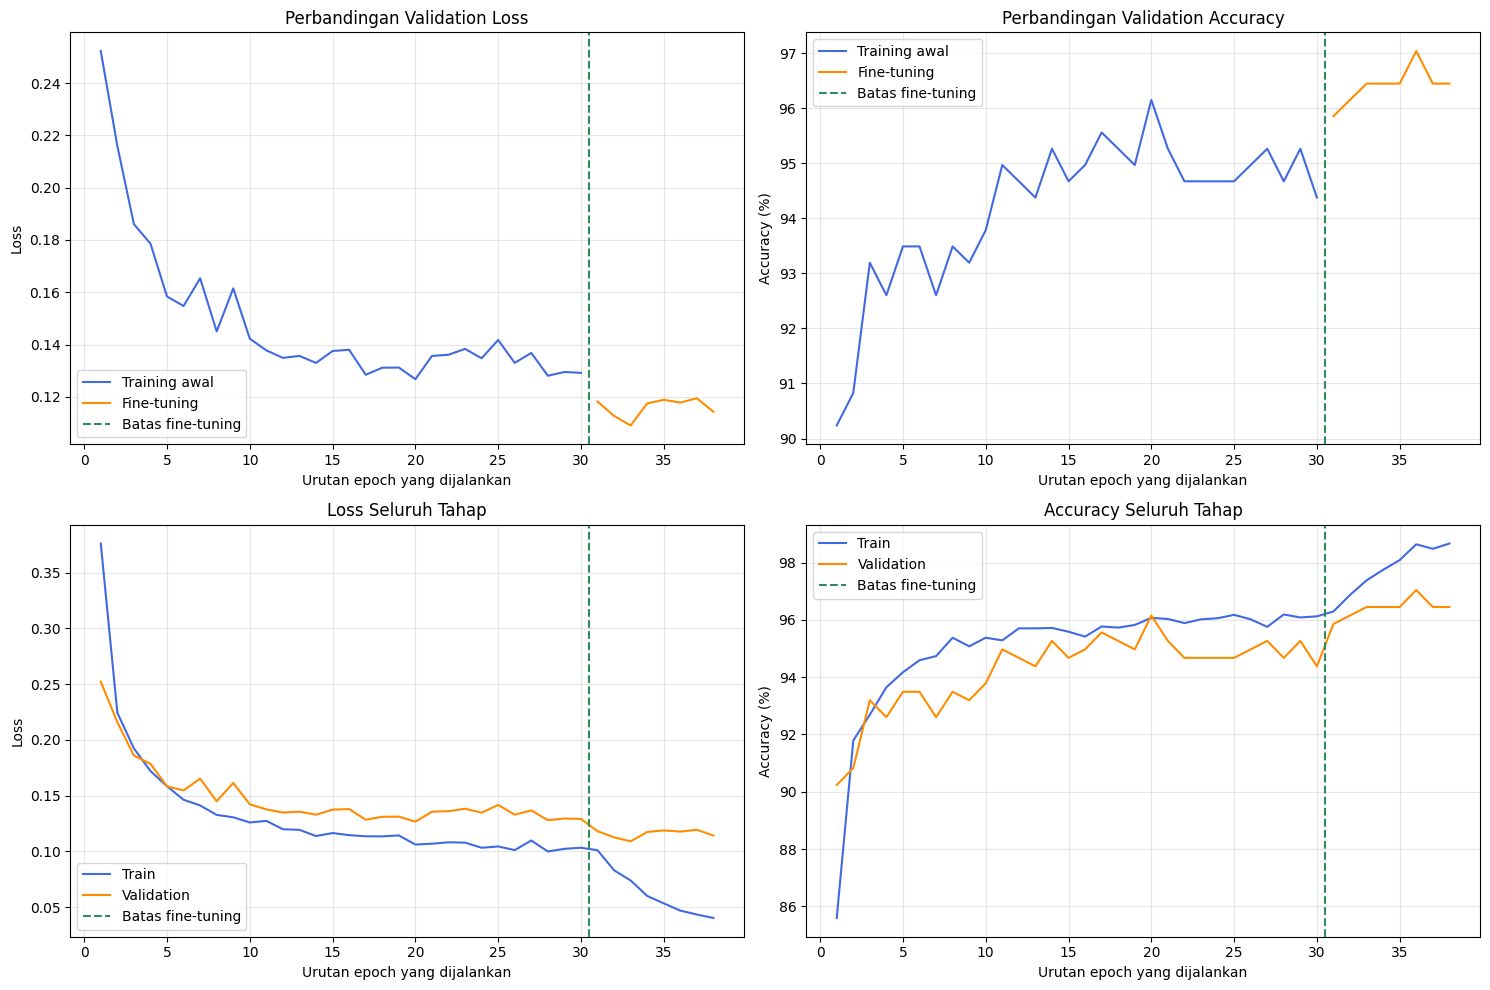

,Tahap,Epoch Terbaik dalam Tahap,Validation Loss Terbaik,Validation Accuracy pada Epoch Terbaik (%)
0,Training awal,20,0.1267,96.1538
1,Fine-tuning,3,0.1090,96.4497


Grafik disimpan di: /content/drive/MyDrive/klasifikasi_buah/eksperimen_01/finetuning_01/perbandingan_training_finetuning.png


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Baca riwayat kedua tahap
riwayat_awal = pd.read_csv(file_riwayat)
riwayat_ft = pd.read_csv(file_riwayat_finetuning)

epoch_awal = range(1, len(riwayat_awal) + 1)

epoch_ft = range(
    len(riwayat_awal) + 1,
    len(riwayat_awal) + len(riwayat_ft) + 1
)

# 2. Gabungkan untuk visualisasi urutan training
riwayat_gabungan = pd.concat(
    [riwayat_awal, riwayat_ft],
    ignore_index=True
)

epoch_gabungan = range(1, len(riwayat_gabungan) + 1)

fig, sumbu = plt.subplots(2, 2, figsize=(15, 10))

# 3. Perbandingan validation loss
sumbu[0, 0].plot(
    epoch_awal,
    riwayat_awal['val_loss'],
    label='Training awal',
    color='royalblue'
)

sumbu[0, 0].plot(
    epoch_ft,
    riwayat_ft['val_loss'],
    label='Fine-tuning',
    color='darkorange'
)

sumbu[0, 0].set_title('Perbandingan Validation Loss')
sumbu[0, 0].set_ylabel('Loss')

# 4. Perbandingan validation accuracy
sumbu[0, 1].plot(
    epoch_awal,
    riwayat_awal['val_accuracy'] * 100,
    label='Training awal',
    color='royalblue'
)

sumbu[0, 1].plot(
    epoch_ft,
    riwayat_ft['val_accuracy'] * 100,
    label='Fine-tuning',
    color='darkorange'
)

sumbu[0, 1].set_title('Perbandingan Validation Accuracy')
sumbu[0, 1].set_ylabel('Accuracy (%)')

# 5. Loss lengkap kedua tahap
sumbu[1, 0].plot(
    epoch_gabungan,
    riwayat_gabungan['loss'],
    label='Train',
    color='royalblue'
)

sumbu[1, 0].plot(
    epoch_gabungan,
    riwayat_gabungan['val_loss'],
    label='Validation',
    color='darkorange'
)

sumbu[1, 0].set_title('Loss Seluruh Tahap')
sumbu[1, 0].set_ylabel('Loss')

# 6. Accuracy lengkap kedua tahap
sumbu[1, 1].plot(
    epoch_gabungan,
    riwayat_gabungan['accuracy'] * 100,
    label='Train',
    color='royalblue'
)

sumbu[1, 1].plot(
    epoch_gabungan,
    riwayat_gabungan['val_accuracy'] * 100,
    label='Validation',
    color='darkorange'
)

sumbu[1, 1].set_title('Accuracy Seluruh Tahap')
sumbu[1, 1].set_ylabel('Accuracy (%)')

# 7. Beri batas antara training awal dan fine-tuning
for ax in sumbu.flat:
    ax.axvline(
        len(riwayat_awal) + 0.5,
        color='seagreen',
        linestyle='--',
        label='Batas fine-tuning'
    )

    ax.set_xlabel('Urutan epoch yang dijalankan')
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()

file_grafik_perbandingan = (
    folder_finetuning / 'perbandingan_training_finetuning.png'
)

plt.savefig(
    file_grafik_perbandingan,
    dpi=200,
    bbox_inches='tight'
)

plt.show()

# 8. Bandingkan model terbaik berdasarkan validation loss
baris_awal = riwayat_awal['val_loss'].idxmin()
baris_ft = riwayat_ft['val_loss'].idxmin()

tabel_perbandingan = pd.DataFrame({
    'Tahap': ['Training awal', 'Fine-tuning'],
    'Epoch Terbaik dalam Tahap': [
        int(riwayat_awal.loc[baris_awal, 'epoch']) + 1,
        int(riwayat_ft.loc[baris_ft, 'epoch']) + 1
    ],
    'Validation Loss Terbaik': [
        riwayat_awal.loc[baris_awal, 'val_loss'],
        riwayat_ft.loc[baris_ft, 'val_loss']
    ],
    'Validation Accuracy pada Epoch Terbaik (%)': [
        riwayat_awal.loc[baris_awal, 'val_accuracy'] * 100,
        riwayat_ft.loc[baris_ft, 'val_accuracy'] * 100
    ]
})

display(tabel_perbandingan.round(4))

print("Grafik disimpan di:", file_grafik_perbandingan)

evaluasi

In [ ]:
# pilih model terbaik
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

riwayat_awal = pd.read_csv(file_riwayat)
riwayat_ft = pd.read_csv(file_riwayat_finetuning)

if riwayat_ft['val_loss'].min() < riwayat_awal['val_loss'].min():
    file_model_dipilih = file_model_finetuning
    tahap_dipilih = 'Fine-tuning'
else:
    file_model_dipilih = file_model_terbaik
    tahap_dipilih = 'Training awal'

model_evaluasi = tf.keras.models.load_model(
    file_model_dipilih,
    compile=False
)

folder_evaluasi = folder_hasil / 'evaluasi_test'
folder_evaluasi.mkdir(parents=True, exist_ok=True)

print("Model dipilih:", tahap_dipilih)
print("File model:", file_model_dipilih)

Model dipilih: Fine-tuning
File model: /content/drive/MyDrive/klasifikasi_buah/eksperimen_01/finetuning_01/model_finetuning_terbaik.keras


In [ ]:
label_asli = []
label_prediksi = []

for gambar_batch, label_batch in dataset_test:
    probabilitas = model_evaluasi(
        gambar_batch,
        training=False
    ).numpy()

    prediksi_batch = np.argmax(
        probabilitas,
        axis=1
    )

    label_asli.extend(label_batch.numpy())
    label_prediksi.extend(prediksi_batch)

label_asli = np.array(label_asli)
label_prediksi = np.array(label_prediksi)

if len(label_asli) == 0:
    raise ValueError("Dataset Test kosong.")

urutan_label = list(range(len(nama_kelas)))

akurasi = accuracy_score(
    label_asli,
    label_prediksi
)

precision, recall, f1, _ = precision_recall_fscore_support(
    label_asli,
    label_prediksi,
    labels=urutan_label,
    average='macro',
    zero_division=0
)

jumlah_benar = int(
    (label_asli == label_prediksi).sum()
)

jumlah_salah = len(label_asli) - jumlah_benar

ringkasan_evaluasi = pd.DataFrame({
    'Metrik': [
        'Accuracy',
        'Precision macro',
        'Recall macro',
        'F1-score macro'
    ],
    'Nilai (%)': [
        akurasi * 100,
        precision * 100,
        recall * 100,
        f1 * 100
    ]
})

display(ringkasan_evaluasi.round(2))

print("Jumlah gambar Test:", len(label_asli))
print("Prediksi benar:", jumlah_benar)
print("Prediksi salah:", jumlah_salah)

ringkasan_evaluasi.to_csv(
    folder_evaluasi / 'ringkasan_metrik.csv',
    index=False
)

,Metrik,Nilai (%)
0,Accuracy,96.67
1,Precision macro,96.74
2,Recall macro,96.67
3,F1-score macro,96.65


Jumlah gambar Test: 180
Prediksi benar: 174
Prediksi salah: 6


In [ ]:
laporan = classification_report(
    label_asli,
    label_prediksi,
    labels=urutan_label,
    target_names=nama_kelas,
    output_dict=True,
    zero_division=0
)

tabel_laporan = pd.DataFrame(laporan).transpose()

display(tabel_laporan.round(4))

tabel_laporan.to_csv(
    folder_evaluasi / 'classification_report.csv'
)

,precision,recall,f1-score,support
Overripe,0.9365,0.9833,0.9593,60.0000
Ripe,0.9821,0.9167,0.9483,60.0000
Unripe,0.9836,1.0000,0.9917,60.0000
accuracy,0.9667,0.9667,0.9667,0.9667
macro avg,0.9674,0.9667,0.9665,180.0000
weighted avg,0.9674,0.9667,0.9665,180.0000


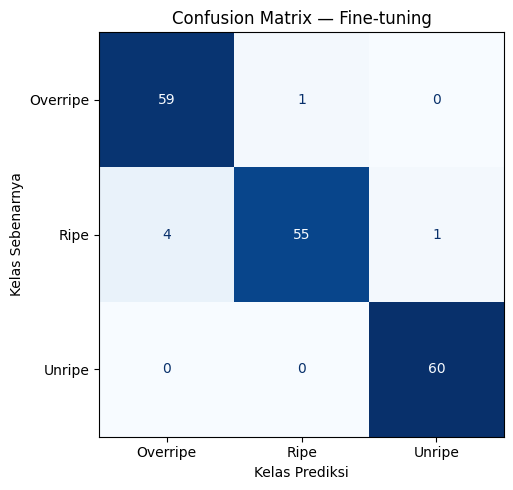

Hasil evaluasi disimpan di: /content/drive/MyDrive/klasifikasi_buah/eksperimen_01/evaluasi_test


In [ ]:
matriks = confusion_matrix(
    label_asli,
    label_prediksi,
    labels=urutan_label
)

fig, ax = plt.subplots(figsize=(6, 5))

tampilan = ConfusionMatrixDisplay(
    confusion_matrix=matriks,
    display_labels=nama_kelas
)

tampilan.plot(
    ax=ax,
    cmap='Blues',
    values_format='d',
    colorbar=False
)

ax.set_title(f'Confusion Matrix — {tahap_dipilih}')
ax.set_xlabel('Kelas Prediksi')
ax.set_ylabel('Kelas Sebenarnya')

plt.tight_layout()

plt.savefig(
    folder_evaluasi / 'confusion_matrix.png',
    dpi=200,
    bbox_inches='tight'
)

plt.show()

print("Hasil evaluasi disimpan di:", folder_evaluasi)

In [ ]:
# Menyiapkan fungsi prediksi menggunakan TensorFlow/Keras

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

def prediksi_buah(lokasi_gambar):
    # Membaca gambar menggunakan PIL
    gambar = Image.open(lokasi_gambar).convert("RGB")

    # Preprocessing: resize gambar sesuai ukuran_gambar (224, 224)
    gambar_resized = gambar.resize(
        (ukuran_gambar[1], ukuran_gambar[0]),
        resample=Image.Resampling.BILINEAR
    )

    # Mengubah ke array numpy dan normalisasi jika diperlukan (EfficientNet menangani normalisasi secara internal)
    array_gambar = np.array(gambar_resized, dtype=np.float32)

    # Menambahkan dimensi batch (1, 224, 224, 3)
    input_tensor = np.expand_dims(array_gambar, axis=0)

    # Melakukan prediksi menggunakan model TensorFlow/Keras
    probabilitas_batch = model_evaluasi(input_tensor, training=False).numpy()
    probabilitas = probabilitas_batch[0]

    # Mengambil indeks dengan probabilitas tertinggi
    indeks_prediksi = np.argmax(probabilitas)

    # Mengubah indeks menjadi nama kelas
    kelas_prediksi = nama_kelas[indeks_prediksi]
    confidence = probabilitas[indeks_prediksi]

    return gambar, kelas_prediksi, confidence, probabilitas

print("Fungsi prediksi berbasis TensorFlow berhasil diperbaiki!")

Fungsi prediksi berbasis TensorFlow berhasil diperbaiki!


In [ ]:

from pathlib import Path

# Folder gambar baru di Google Drive
folder_gambar = Path(
    "/content/drive/MyDrive/TUGAS/AI/KLASIFIKASI BUAH/baru"
)

# Mengambil daftar gambar
ekstensi = {".jpg", ".jpeg", ".png", ".webp"}

daftar_gambar = sorted([
    file for file in folder_gambar.iterdir()
    if file.is_file() and file.suffix.lower() in ekstensi
])

print("Jumlah gambar ditemukan:", len(daftar_gambar))

for gambar in daftar_gambar:
    print(gambar.name)


Jumlah gambar ditemukan: 3
images (1).jpg
images (2).jpg
images.jpg


In [ ]:

import pandas as pd

hasil_pengujian = []

for lokasi in daftar_gambar:

    gambar, prediksi, confidence, probabilitas = prediksi_buah(
        lokasi
    )

    hasil_pengujian.append({
        "nama_file": lokasi.name,
        "prediksi": prediksi,
        "confidence": round(confidence * 100, 2)
    })

df_pengujian = pd.DataFrame(hasil_pengujian)

display(df_pengujian)


,nama_file,prediksi,confidence
0,images (1).jpg,Overripe,100.000000
1,images (2).jpg,Ripe,98.949997
2,images.jpg,Ripe,63.270000


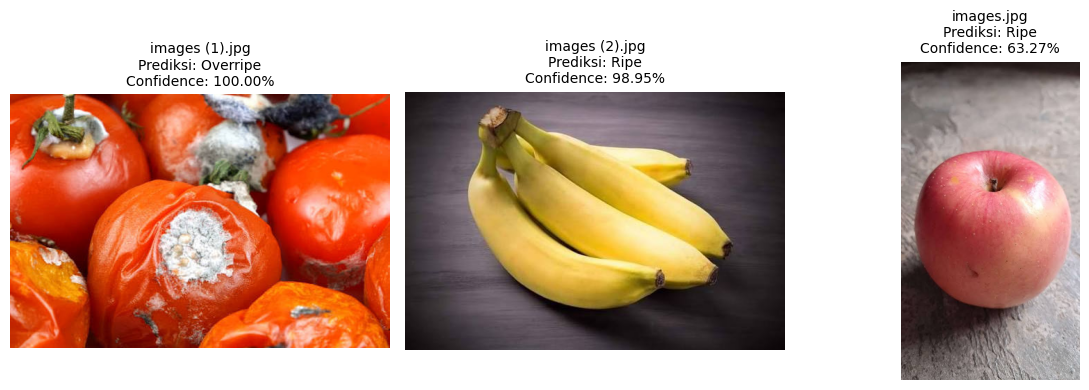

In [ ]:

import matplotlib.pyplot as plt
import math

jumlah_gambar = len(daftar_gambar)

if jumlah_gambar == 0:
    print("Belum ada gambar untuk ditampilkan.")

else:
    kolom = 3
    baris = math.ceil(jumlah_gambar / kolom)

    fig, axes = plt.subplots(
        baris,
        kolom,
        figsize=(12, baris * 4),
        squeeze=False
    )

    for ax in axes.flat:
        ax.axis("off")

    for i, lokasi in enumerate(daftar_gambar):

        gambar, prediksi, confidence, probabilitas = prediksi_buah(
            lokasi
        )

        ax = axes.flat[i]

        ax.imshow(gambar)

        ax.set_title(
            f"{lokasi.name}\n"
            f"Prediksi: {prediksi}\n"
            f"Confidence: {confidence:.2%}",
            fontsize=10
        )

    plt.tight_layout()
    plt.show()
